### Objetivo

Desenvolver e comparar modelos de Machine Learning
para identificar a presença de doenças cardiovasculares
a partir de características clínicas dos pacientes.

O projeto utiliza um conjunto de dados com aproximadamente
70.000 pacientes e contempla análise exploratória,
pré-processamento, engenharia de atributos, treinamento,
avaliação e interpretação dos modelos.

### Organização do notebook

1. Carregamento dos dados
2. Análise exploratória (EDA)
3. Pré-processamento e engenharia de atributos
4. Comparação dos modelos na validação
5. Avaliação final e limiar de decisão
6. Interpretação dos resultados (SHAP)
7. Conclusão

In [9]:
from cardio.config import DATA_PATH
from cardio.data.loader import load_dataset
from cardio.data.preprocessing import clean, load_splits
from cardio.features.build import add_features, get_feature_names
import cardio.visualization.eda as eda

<module 'cardio.features' from 'C:\\Users\\miche\\OneDrive\\Documentos\\Python\\Cardio\\src\\cardio\\features.py'>

70.000 → 68.509 linhas (1.491 removidas, 2,13%)
  - Duplicados (ignorando o id): 24
  - Sistólica fora de 70–250 mmHg: 229
  - Diastólica fora de 40–200 mmHg: 997
  - Diastólica >= sistólica: 103
  - Altura fora de 130–210 cm: 89
  - Peso fora de 35–200 kg: 16
  - IMC fora de 15–60 kg/m²: 33
Taxa de doença: 49,97% → 49,49%


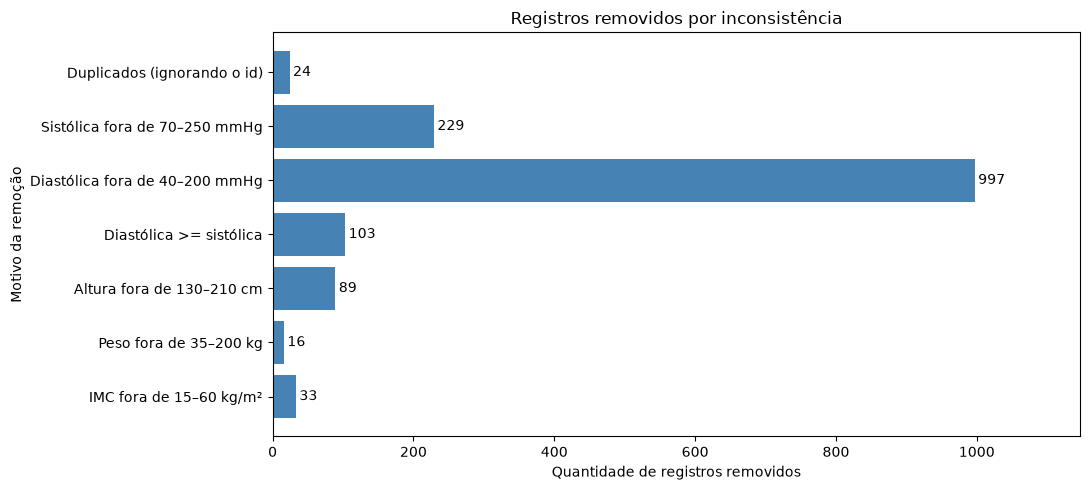

Conjunto A: 11 atributos
Conjunto B: 16 atributos
70.000 → 68.509 linhas (1.491 removidas, 2,13%)
  - Duplicados (ignorando o id): 24
  - Sistólica fora de 70–250 mmHg: 229
  - Diastólica fora de 40–200 mmHg: 997
  - Diastólica >= sistólica: 103
  - Altura fora de 130–210 cm: 89
  - Peso fora de 35–200 kg: 16
  - IMC fora de 15–60 kg/m²: 33
Taxa de doença: 49,97% → 49,49%
Treino: 47.955 pacientes (70,00%), 49,48% com doença
Validação: 10.277 pacientes (15,00%), 49,49% com doença
Teste: 10.277 pacientes (15,00%), 49,49% com doença


In [10]:

df = load_dataset(DATA_PATH)
df_clean = clean(df, verbose=True)
eda.plot_dados_invalidos(df_clean)

df_features = add_features(df_clean)

df_features[
    ["ap_hi", "ap_lo", "categoria_pressao", "imc", "pressao_pulso", "pam"]
].head(10)

features_a = get_feature_names("A")
features_b = get_feature_names("B")

print(f"Conjunto A: {len(features_a)} atributos")
print(f"Conjunto B: {len(features_b)} atributos")


X_train, X_val, X_test, y_train, y_val, y_test = load_splits(
    feature_set="A",
    save_ids=True,
    verbose=True
)


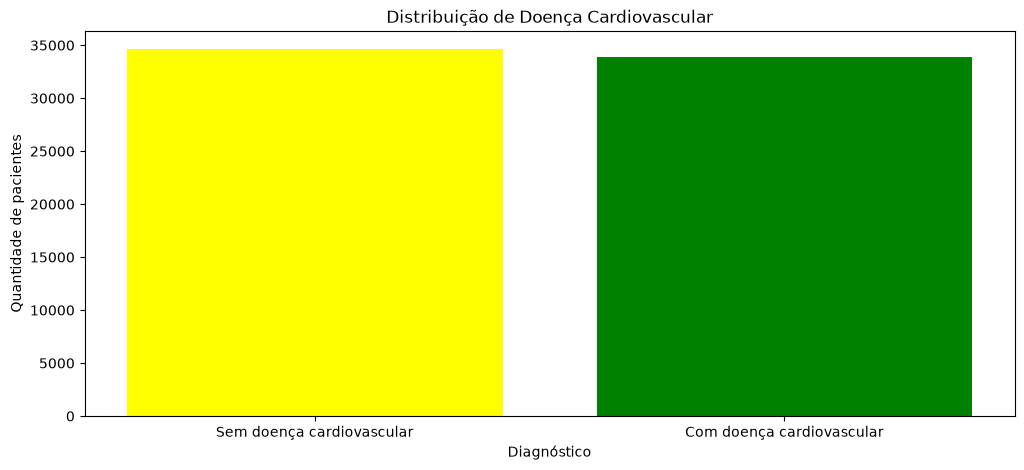

In [3]:
eda.plot_distribuicao_cardio(df_clean)

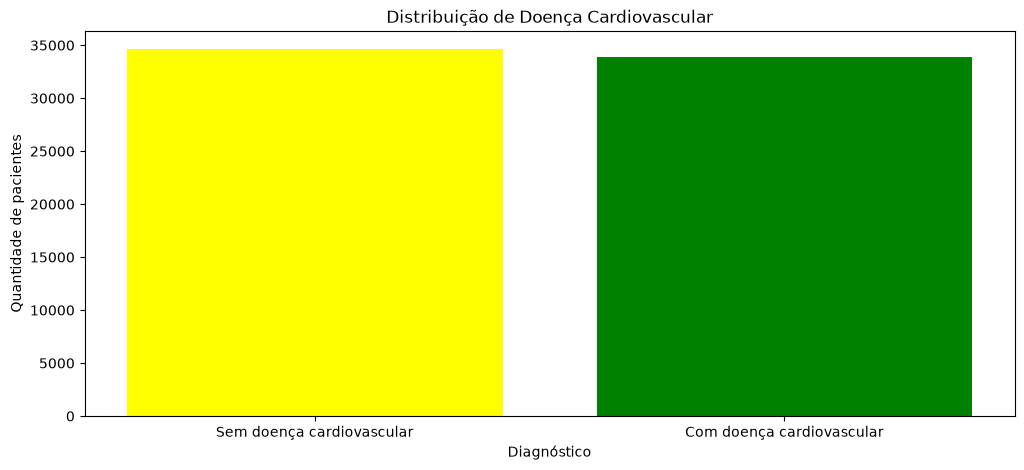

In [4]:
eda.plot_distribuicao_cardio(df_clean)


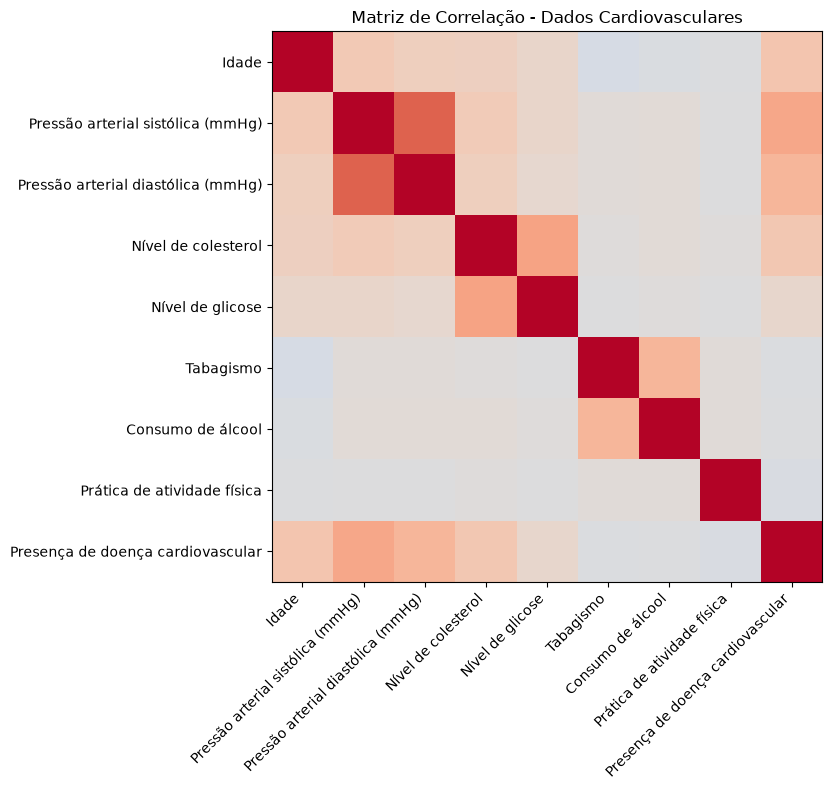

In [5]:
eda.plot_matriz_correlacao(df_clean)


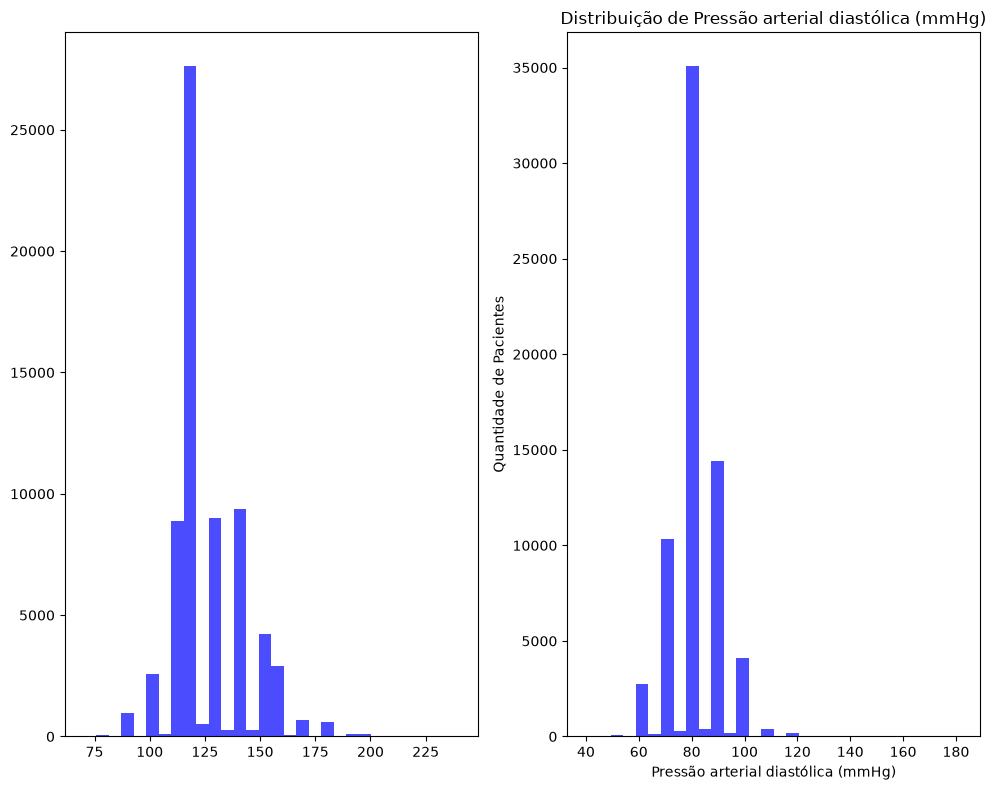

In [6]:
eda.plot_distribuicao_pressao_arterial(df_clean)